## Lab 01 Sentiment Analysis Using Traditional Machine Learning

In [ ]:
# Importing the relevant libraries
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Download English stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

### 1. Load the dataset.

In [ ]:
df = pd.read_csv(
    'imdb_labelled.txt',
    sep='\t',
    header=None,
    names=['text', 'label']
)

# Display the first five records
print(df.head())

# Check dataset information
print("\nDataset Information:")
print(df.info())

# Check the number of positive and negative reviews
print("\nSentiment Distribution:")
print(df['label'].value_counts())

                                                text  label
0  A very, very, very slow-moving, aimless movie ...      0
1  Not sure who was more lost - the flat characte...      0
2  Attempting artiness with black & white and cle...      0
3       Very little music or anything to speak of.        0
4  The best scene in the movie was when Gerardo i...      1

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    748 non-null    object
 1   label   748 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 11.8+ KB
None

Sentiment Distribution:
label
1    386
0    362
Name: count, dtype: int64


### 2. Perform base text preprocessing.

In [ ]:
def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Replace punctuation and unnecessary characters with spaces
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # 3. Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Create clean-text column
df['clean_text'] = df['text'].apply(preprocess_text)

# Compare original and preprocessed text
print(df[['text', 'clean_text']].head())

                                                text  \
0  A very, very, very slow-moving, aimless movie ...   
1  Not sure who was more lost - the flat characte...   
2  Attempting artiness with black & white and cle...   
3       Very little music or anything to speak of.     
4  The best scene in the movie was when Gerardo i...   

                                          clean_text  
0  a very very very slow moving aimless movie abo...  
1  not sure who was more lost the flat characters...  
2  attempting artiness with black white and cleve...  
3          very little music or anything to speak of  
4  the best scene in the movie was when gerardo i...  


### 3. Explore the text data.

3.1 Display positive and negative examples

In [ ]:
## Display three positive examples
print("Positive Examples:\n")

positive_examples = df[df['label'] == 1]['clean_text'].head(3)

for review in positive_examples:
    print("-", review)

# Display three negative examples
print("\nNegative Examples:\n")

negative_examples = df[df['label'] == 0]['clean_text'].head(3)

for review in negative_examples:
    print("-", review)

Positive Examples:

- the best scene in the movie was when gerardo is trying to find a song that keeps running through his head
- saw the movie today and thought it was a good effort good messages for kids
- loved the casting of jimmy buffet as the science teacher

Negative Examples:

- a very very very slow moving aimless movie about a distressed drifting young man
- not sure who was more lost the flat characters or the audience nearly half of whom walked out
- attempting artiness with black white and clever camera angles the movie disappointed became even more ridiculous as the acting was poor and the plot and lines almost non existent


3.2 Identify frequently occurring words

In [ ]:
# Load English stopwords
stop_words = set(stopwords.words('english'))

# Keep important negation words
stop_words = stop_words - {'not', 'no', 'never'}

# Separate positive and negative reviews
positive_text = ' '.join(
    df[df['label'] == 1]['clean_text']
)

negative_text = ' '.join(
    df[df['label'] == 0]['clean_text']
)

# Split into individual words
positive_words = positive_text.split()
negative_words = negative_text.split()

# Remove stopwords
positive_words = [
    word for word in positive_words
    if word not in stop_words
]

negative_words = [
    word for word in negative_words
    if word not in stop_words
]

# Identify the 10 most frequent words
positive_freq = Counter(positive_words).most_common(10)
negative_freq = Counter(negative_words).most_common(10)

print("Top Positive Words:", positive_freq)
print("\nTop Negative Words:", negative_freq)

Top Positive Words: [('film', 91), ('movie', 87), ('0', 46), ('good', 36), ('one', 35), ('great', 29), ('1', 25), ('really', 23), ('like', 23), ('well', 22)]

Top Negative Words: [('1', 96), ('movie', 95), ('0', 94), ('film', 72), ('bad', 64), ('not', 52), ('one', 44), ('even', 33), ('time', 26), ('no', 25)]


3.3 Visualise frequently occurring words

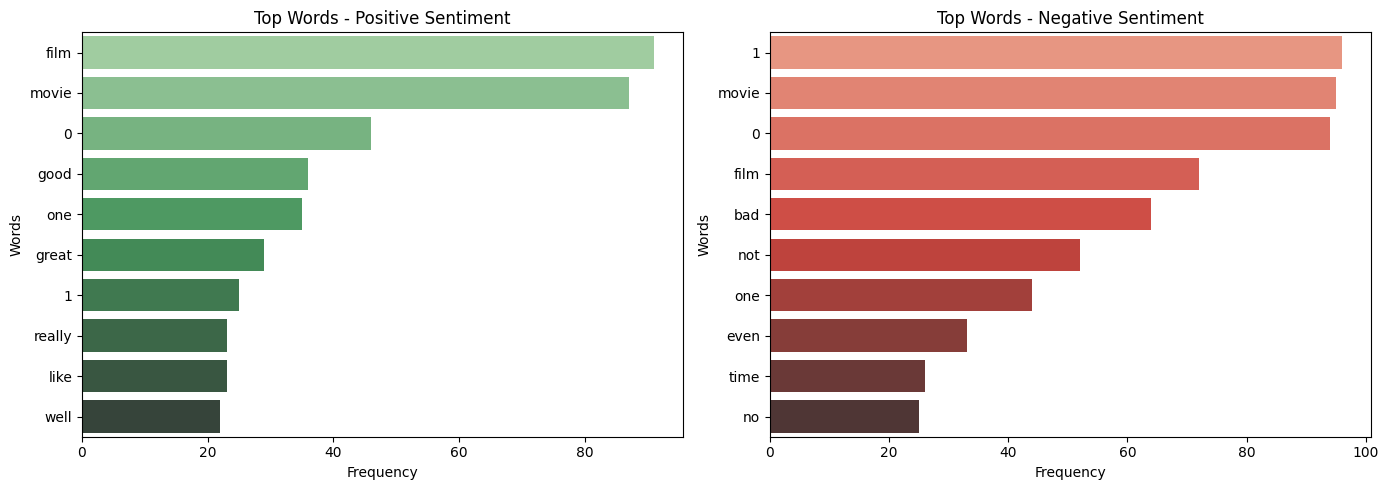

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Positive sentiment words
sns.barplot(
    x=[item[1] for item in positive_freq],
    y=[item[0] for item in positive_freq],
    hue=[item[0] for item in positive_freq],
    palette="Greens_d",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Top Words - Positive Sentiment")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Words")

# Negative sentiment words
sns.barplot(
    x=[item[1] for item in negative_freq],
    y=[item[0] for item in negative_freq],
    hue=[item[0] for item in negative_freq],
    palette="Reds_d",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Top Words - Negative Sentiment")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Words")

plt.tight_layout()
plt.show()

### 4. Split the dataset

In [ ]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'],
    df['label'],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 598
Testing samples: 150


### 5. Create BOW representation.

In [ ]:
# Create Bag of Words representation
vectorizer = CountVectorizer()

# Learn vocabulary from training data and transform it
X_train_vec = vectorizer.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_vec = vectorizer.transform(X_test)

print("Training data shape:", X_train_vec.shape)
print("Testing data shape:", X_test_vec.shape)

# Display some vocabulary words
print("\nSample vocabulary:")
print(list(vectorizer.get_feature_names_out()[:20]))

Training data shape: (598, 2637)
Testing data shape: (150, 2637)

Sample vocabulary:
['10', '12', '13', '15', '17', '18th', '1928', '1948', '1949', '1971', '1980', '1995', '1998', '20', '2006', '20th', '25', '30', '40', '50']


### 6. Train a ML model(SVM,Logistic Regression)

In [ ]:
# Define machine learning models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Support Vector Machine": SVC(kernel='linear')
}

# Store trained models and predictions
trained_models = {}
predictions = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_vec, y_train)

    # Predict test data
    preds = model.predict(X_test_vec)

    # Store results
    trained_models[name] = model
    predictions[name] = preds

    print(f"\n{name} training completed.")


Logistic Regression training completed.

Support Vector Machine training completed.


### 7. Evaluate the model's performance.

7.1 Classification report

In [ ]:
for name, preds in predictions.items():

    print(f"\n===== {name} Performance =====")

    # Accuracy
    accuracy = accuracy_score(y_test, preds)
    print(f"Accuracy: {accuracy:.4f}")

    # Precision, Recall and F1-score
    print(
        classification_report(
            y_test,
            preds,
            target_names=['Negative', 'Positive'],
            zero_division=0
        )
    )


===== Logistic Regression Performance =====
Accuracy: 0.7200
              precision    recall  f1-score   support

    Negative       0.72      0.70      0.71        73
    Positive       0.72      0.74      0.73        77

    accuracy                           0.72       150
   macro avg       0.72      0.72      0.72       150
weighted avg       0.72      0.72      0.72       150


===== Support Vector Machine Performance =====
Accuracy: 0.7067
              precision    recall  f1-score   support

    Negative       0.70      0.70      0.70        73
    Positive       0.71      0.71      0.71        77

    accuracy                           0.71       150
   macro avg       0.71      0.71      0.71       150
weighted avg       0.71      0.71      0.71       150



7.2 Confusion matrix

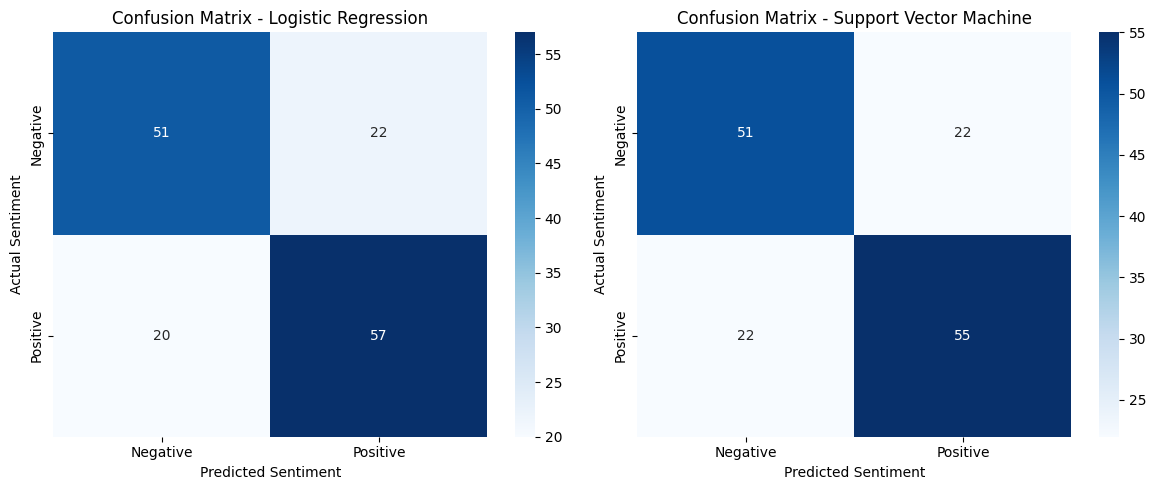

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, preds) in zip(axes, predictions.items()):

    # Calculate confusion matrix
    cm = confusion_matrix(y_test, preds)

    # Display confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {name}')
    ax.set_xlabel('Predicted Sentiment')
    ax.set_ylabel('Actual Sentiment')

plt.tight_layout()
plt.show()

### 8. Test the model with new sentences.

In [ ]:
# Select Logistic Regression model
best_model = trained_models["Logistic Regression"]

# Function to predict sentiment
def predict_sentiment(custom_text):

    # Preprocess input text
    cleaned_text = preprocess_text(custom_text)

    # Convert text into BoW representation
    vectorized_text = vectorizer.transform([cleaned_text])

    # Predict sentiment
    prediction = best_model.predict(vectorized_text)[0]

    # Convert numerical prediction into sentiment label
    sentiment = "Positive" if prediction == 1 else "Negative"

    return sentiment


# Test with new sentences
test_input_1 = "The movie was absolutely brilliant with stunning visuals!"

test_input_2 = "Horrible pacing, completely wasted my time."

# Display predictions
print(
    f"'{test_input_1}' -> {predict_sentiment(test_input_1)}"
)

print(
    f"'{test_input_2}' -> {predict_sentiment(test_input_2)}"
)

'The movie was absolutely brilliant with stunning visuals!' -> Positive
'Horrible pacing, completely wasted my time.' -> Negative
